# Synthetic Little Ice Age temperature reconstruction — Great Aletsch Glacier

**Goal.** Repeat [`LIA_temperature_inversion.ipynb`](LIA_temperature_inversion.ipynb) on the *same
timeline* (start the model in 1500 from the 2017 geometry, observe the ice extent in the years listed in `EPOCHS`:
1750, 1880, 1926, 1957, 1980 and 2017) but with **generated DEMs instead of the real ones**, so that the
temperature history we are trying to recover is known and the reconstruction can be scored
against it.

This is a *twin experiment*:

1. **True climate.** A flat temperature (`T_FLAT`) that bends upward along a GELU curve to `T_2017`
   in 2017 (`utils.temperature_functions.flat_then_gelu_series`, the same generator as in
   [`synthetic_temperature_reference.ipynb`](synthetic_temperature_reference.ipynb)). Section 2.1
   checks how realistic the resulting glaciers are.
2. **Synthetic DEMs.** Run the forward model from 1500 to 2017, starting from the observed 2017
   DEM, under that climate, and keep the ice thickness at the observation years.
3. **Inversion.** Forget the truth. Starting from a flat guess, invert for `T_lowest(t)` with the
   same extent-only objective, control nodes and precipitation / melt factor / tau_ref / Arrhenius
   factor as the real-data notebook.
4. **Comparison.** Plot the recovered temperature history against the truth, and the recovered
   extents against the synthetic ones.

**What the twin experiment can and cannot say.** The same model generates the data and inverts
them, with identical precipitation, melt factor, tau_ref and Arrhenius factor, so there is *no
model error and no observation noise*. The result is therefore a best case for the real-data
inversion: whatever is not recovered here is limited by the information in extent-only
observations, by the 50-year control-node parameterisation, or by the optimiser's budget, not by
anything wrong with the physics. To keep the parameterisation from being matched too
conveniently, the truth is generated with a **10-year** forcing step while the inversion
controls **50-year** nodes.

**Two differences from the real-data notebook, on purpose.**

- *No analysis mask.* The real run masks out the high accumulation basin, where the real glacier
  sheds ice by avalanching and the model grows a thin veneer that no temperature can remove. A
  model-generated truth has no such error, so there is nothing to mask.
- *Optimiser settings* (see Section 4): initial guess 7.0 °C and learning rate 0.05.

**Compute.** Generating the DEMs takes about 2 minutes and is always re-run. The inversion is the expensive
part (the real-data run took ~167 s per iteration on an RTX 4090). Set `RUN_INVERSION = False` in
the setup cell to load a cached run from `RESULTS` instead of recomputing it.

In [1]:
import json
import os
import time

import matplotlib.pyplot as plt
import netCDF4
import numpy as np
import torch

if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")   # repo root, when this notebook is opened from notebooks/

RUN_INVERSION = True   # False: load the cached inversion from RESULTS instead of re-running it (hours)
RESULTS = "results/synthetic_lia_1500_2017_2"
os.makedirs(RESULTS, exist_ok=True)

# Fixed model parameters: the same for the synthetic truth and for the inversion.
BASE = dict(
    melt_factor=2.7 / 12,   # m ice eq / (deg C . month), PDD ablation factor
    precip=1.8,             # m w.e./yr, uniform over the domain
    T_s=10.0,               # seasonal temperature amplitude, deg C
    tau_ref=0.2154,         # MPa, Weertman reference basal shear stress (IGM default)
    arrhenius=78.0,         # MPa^-3 yr^-1, Glen's flow law factor
)

# Timeline: identical to LIA_temperature_inversion.ipynb.
T_START, T_END = 1500, 2017
EPOCHS = [1750, 1880, 1926, 1957, 1980, 2017]   # years with a (synthetic) DEM
NODE_FREQ = 50                            # control-node spacing of the inversion, years

# The true climate: flat at T_FLAT, then a GELU-shaped rise reaching T_2017 in 2017.
T_FLAT, T_2017, SHARPNESS = 7.2, 8.56, 3.0   # flat level, value reached in 2017, GELU steepness
# T_FLAT, T_2017 = 7.40, 8.80   # a warmer truth that keeps the terminus off the grid edge, see Section 2.1
TRUTH_FREQ = 10                           # step of the forcing that generates the DEMs, years

# Inversion settings.
INIT_T = 7.0         # flat initial guess, deg C
LR = 0.05            # Adam learning rate
REG_LAMBDA = 0.01    # smoothness penalty on the control
N_ITERS = 50

# Colours (fixed order: truth, recovered, target).
C_TRUE, C_REC, C_TARGET, C_GREY = "#2a78d6", "#eb6834", "#1baf7a", "#6b6b68"

/home/klleshi/miniconda3/envs/IGEM/lib/python3.12/site-packages/torch/cuda/__init__.py:61: FutureWarning: The pynvml package is deprecated. Please install nvidia-ml-py instead. If you did not install pynvml directly, please report this to the maintainers of the package that installed pynvml for you.
  import pynvml  # type: ignore[import]


## 1. The true climate

`flat_then_gelu_series` holds `T_FLAT` for the first third of the samples, then rises along a
GELU curve to `T_FLAT + slope`. GELU is almost flat for negative arguments and almost linear for
positive ones, so the result is a hockey stick: exactly `T_FLAT` for the first third of the
samples, then a slight dip below it (GELU is negative for negative arguments; the dip is about
0.09 °C for the default values) before the warming takes over and runs roughly linearly up to
`T_2017` in 2017.

The curve is evaluated once a year (518 samples, 1500-2017). The model, however, holds
temperature constant between control updates, so what drives it is the **mean of the annual curve
over each step**. Two such series are computed (and printed below, not plotted):

- `T_truth`: 10-year steps (52 values) -- this generates the synthetic DEMs.
- `T_target`: 50-year steps (11 values) -- the best an 11-node, 50-year control can possibly
  represent. It is the reference for the convergence diagnostics in Sections 4-5 (the loss at these
  nodes, and the node RMSE); the plots compare against the smooth curve itself.

annual curve: 7.20 C in 1500, minimum 7.12 C in 1801, 7.41 C in 1880, 8.26 C in 1980, 8.56 C in 2017
50-yr target nodes: [7.2  7.2  7.2  7.2  7.18 7.14 7.15 7.38 7.78 8.21 8.49]


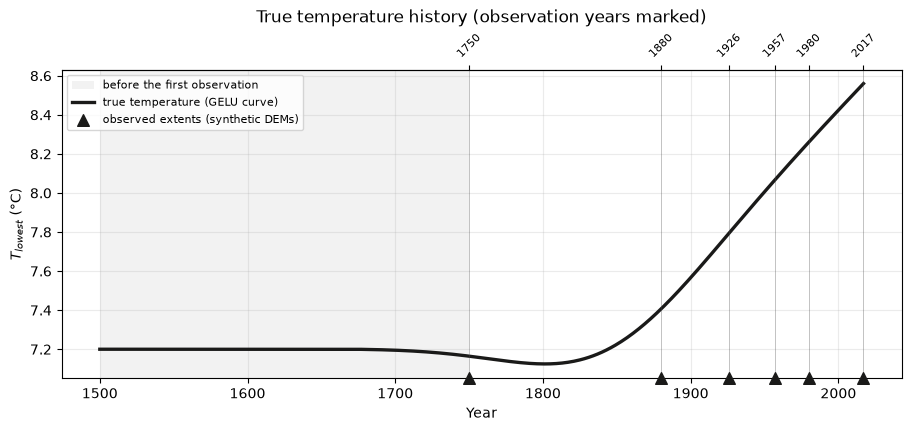

In [2]:
from utils.temperature_functions import flat_then_gelu_series

years = np.arange(T_START, T_END + 1)
T_annual = flat_then_gelu_series(len(years), 1.0, flat_value=T_FLAT,
                                 slope=T_2017 - T_FLAT, sharpness=SHARPNESS).numpy()

def node_means(freq):
    '''Mean of the annual curve over each interval [t_k, t_k + freq): the value a piecewise-constant forcing should hold.'''
    n = int((T_END - T_START) // freq) + 1
    return np.array([T_annual[(years >= T_START + k * freq) & (years < T_START + (k + 1) * freq)].mean()
                     for k in range(n)])

T_truth = node_means(TRUTH_FREQ)     # drives the synthetic run
T_target = node_means(NODE_FREQ)     # what the 50-year inversion nodes should find
print(f"annual curve: {T_annual[0]:.2f} C in {T_START}, minimum {T_annual.min():.2f} C in {years[T_annual.argmin()]}, "
      f"{T_annual[years == 1880][0]:.2f} C in 1880, {T_annual[years == 1980][0]:.2f} C in 1980, "
      f"{T_annual[-1]:.2f} C in {T_END}")
print("50-yr target nodes:", np.round(T_target, 2))

C_INK = "#1a1a19"
fig, ax = plt.subplots(figsize=(9, 4.2), constrained_layout=True)
ax.axvspan(T_START, EPOCHS[0], color="0.5", alpha=0.10, lw=0, label="before the first observation")
ax.plot(years, T_annual, color=C_INK, lw=2.4, label="true temperature (GELU curve)")
for y in EPOCHS:
    ax.axvline(y, color="0.3", lw=0.6, alpha=0.4)
ax.scatter(EPOCHS, np.zeros(len(EPOCHS)), transform=ax.get_xaxis_transform(), marker="^", s=70,
           color=C_INK, clip_on=False, zorder=7, label="observed extents (synthetic DEMs)")
sec = ax.secondary_xaxis("top", functions=(lambda v: v, lambda v: v)); sec.set_xticks(EPOCHS); sec.tick_params(labelrotation=45, labelsize=8)
ax.set_xlabel("Year")
ax.set_ylabel("$T_{lowest}$ (°C)")
ax.set_title("True temperature history (observation years marked)", pad=34)
ax.grid(alpha=0.25)
ax.legend(fontsize=8, loc="upper left")
fig.savefig(f"{RESULTS}/true_temperature.png", dpi=150, bbox_inches="tight")
plt.show()

## 2. Generating the DEMs

The forward model is built exactly as in the real-data notebook -- IGM `SIADecompNet` emulator,
parametric PDD mass balance, ice-mask-limited domain -- and started in 1500 from the **observed
2017 thickness**. Running it under `T_truth` and saving a snapshot at each observation year gives
one synthetic thickness map per observation year. They are *not* the real DEMs: the 2017 snapshot is what the model
makes of 517 years of this climate, and it need not coincide with the 2017 geometry it started
from.

The 1750 epoch has no real DEM in `geology.nc`: it only exists as synthetic data, so it is left out
of the comparisons with real DEMs in Section 2.1.

In [3]:
from config.read_config import parse_arguments
from core.emulator import load_emulator
from core.glacier import GlacierDynamicsCheckpointed
from core.inversion import invert_extent
from core.utils import device

# visualization/plots.py (pulled in by core.glacier) calls matplotlib.use("Agg") on import, which would stop
# every later figure from showing in the notebook; switch back to the inline backend.
get_ipython().run_line_magic("matplotlib", "inline")

def load_real(path="data/geology.nc"):
    nc = netCDF4.Dataset(path)
    topg = torch.tensor(nc["topg"][:], dtype=torch.float32, device=device)
    surf = lambda y: torch.tensor(nc[f"surf_{y}"][:], dtype=torch.float32, device=device) - topg
    # epochs without a real DEM in geology.nc (e.g. 1750) only exist as synthetic data
    thk = {y: surf(y) for y in EPOCHS if f"surf_{y}" in nc.variables}
    out = dict(topg=topg, icemask=torch.tensor(nc["icemask"][:], dtype=torch.float32, device=device),
               x=np.asarray(nc["x"][:]), y=np.asarray(nc["y"][:]), thk=thk, H_init=surf(2017))
    nc.close()
    return out

def make_args(freq):
    args = parse_arguments([])
    args.t_start = torch.tensor(float(T_START))
    args.ttot = torch.tensor(float(T_END))
    args.vis_freq = float(freq)          # control-node spacing, years
    return args

def build_glacier(freq):
    return GlacierDynamicsCheckpointed(
        real["topg"], real["H_init"], ice_mask=real["icemask"], device=device,
        args=make_args(freq), emulator=emulator,
        tau_ref=BASE["tau_ref"], arrhenius=BASE["arrhenius"])

real = load_real()
emulator = load_emulator(make_args(NODE_FREQ).emulator_path, device=device)
x_km, y_km = real["x"] / 1000, real["y"] / 1000
ext = [x_km.min(), x_km.max(), y_km.min(), y_km.max()]
print("Grid:", tuple(real["topg"].shape), " y ascending:", bool(y_km[1] > y_km[0]),
      " Modern ice volume:", f"{float(real['H_init'].sum()) * 1e4 / 1e9:.2f} km3")

You are working on cuda:1 device
Grid: (225, 132)  y ascending: True  Modern ice volume: 13.72 km3


In [4]:
truth_model = build_glacier(TRUTH_FREQ)
t0 = time.time()
with torch.no_grad():
    saved, _ = truth_model(
        precip_tensor=BASE["precip"],
        T_m_lowest=torch.tensor(T_truth, dtype=torch.float32, device=device).view(-1, 1),
        T_s=BASE["T_s"], melt_factor=BASE["melt_factor"],
        save_times=[float(y) for y in EPOCHS])
missing = [y for y in EPOCHS if saved.get(float(y)) is None]
assert not missing, f"no snapshot saved for {missing}"
syn = {y: saved[float(y)] for y in EPOCHS}
print(f"synthetic DEMs generated in {time.time() - t0:.0f} s")
np.savez(f"{RESULTS}/synthetic_obs.npz", x=real["x"], y=real["y"],
         topg=real["topg"].cpu().numpy(), icemask=real["icemask"].cpu().numpy(),
         T_truth=T_truth, T_target=T_target,
         **{f"syn_{y}": syn[y].cpu().numpy() for y in EPOCHS},
         **{f"real_{y}": real["thk"][y].cpu().numpy() for y in real["thk"]})

syn_np = {y: syn[y].cpu().numpy() for y in EPOCHS}
real_np = {y: real["thk"][y].cpu().numpy() for y in real["thk"]}   # only the epochs that have a real DEM
topg_np = real["topg"].cpu().numpy()

/home/klleshi/Documents/InvertedGlacierEvolutionModel/core/glacier.py:113: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  t_last_update = torch.tensor(self.t_start, device=self.device)
/home/klleshi/miniconda3/envs/IGEM/lib/python3.12/site-packages/torch/_dynamo/eval_frame.py:745: UserWarning: torch.utils.checkpoint: the use_reentrant parameter should be passed explicitly. In version 2.5 we will raise an exception if use_reentrant is not passed. use_reentrant=False is recommended, but if you need to preserve the current default behavior, you can pass use_reentrant=True. Refer to docs for more details on the differences between the two variants.
  return fn(*args, **kwargs)
/home/klleshi/miniconda3/envs/IGEM/lib/python3.12/site-packages/torch/utils/checkpoint.py:87: UserWarning: None of the inputs have requires_grad=True. Gradients will b

synthetic DEMs generated in 51 s


### 2.1 Do the synthetic geometries look like Aletsch?

The reason for choosing 6.14 -> 7.50 °C was to get extents close to the observed DEMs, so check
that directly: area, volume and the lowest ice-covered elevation (a proxy for terminus position)
against the real DEM at each epoch, and the overlap (IoU) of the two extents.

In [5]:
BOUNDARY_ROWS = 5   # utils.emulator_tools.apply_boundary_condition ramps ice to 0 over the outer 5 rows

def stats(thk):
    ice = thk > 1.0
    terminus_km = np.where(ice.any(axis=1))[0].min() * 0.1   # distance of the tongue's end from the grid's southern edge
    return ice.sum() * 0.01, thk.sum() * 1e4 / 1e9, terminus_km          # km2, km3, km

print(f"{'':>6}{'area km2':>18}{'volume km3':>18}{'terminus, km from edge':>26}")
print(f"{'year':>6}{'real':>9}{'synth':>9}{'real':>9}{'synth':>9}{'real':>13}{'synth':>13}{'IoU':>8}")
pinned = []
for y in EPOCHS:
    as_, vs, ts = stats(syn_np[y])
    if y in real_np:
        ar, vr, tr = stats(real_np[y])
        s, r = syn_np[y] > 1, real_np[y] > 1
        print(f"{y:>6}{ar:9.1f}{as_:9.1f}{vr:9.2f}{vs:9.2f}{tr:13.1f}{ts:13.1f}{(s & r).sum() / (s | r).sum():8.3f}")
    else:   # no real DEM for this epoch (e.g. 1750): synthetic columns only
        print(f"{y:>6}{'-':>9}{as_:9.1f}{'-':>9}{vs:9.2f}{'-':>13}{ts:13.1f}{'-':>8}")
    if ts < (BOUNDARY_ROWS + 1) * 0.1:
        pinned.append(y)
if pinned:
    print(f"\nWARNING: in {pinned} the synthetic terminus sits inside the {BOUNDARY_ROWS}-row boundary zone of the grid. "
          f"The glacier wants to extend past the model domain, so the domain edge, not the climate, is holding the terminus, "
          f"and the terminus carries no temperature signal.")

print()
for name, d in (("real", real_np), ("synthetic", syn_np)):
    a0, v0, _ = stats(d[1880]); a1, v1, _ = stats(d[2017])
    print(f"{name:>9}, 1880 -> 2017: area {(a1 / a0 - 1) * 100:+5.1f}%   volume {(v1 / v0 - 1) * 100:+5.1f}%")

                area km2        volume km3    terminus, km from edge
  year     real    synth     real    synth         real        synth     IoU
  1750        -     96.0        -    18.94            -          1.8       -
  1880     96.1     97.5    20.67    19.53          1.1          1.1   0.917
  1926     95.1     96.7    18.78    18.70          2.2          1.4   0.940
  1957     93.2     95.2    17.22    17.68          2.7          1.9   0.937
  1980     93.1     93.6    16.67    16.73          3.2          2.4   0.941
  2017     90.8     90.6    13.72    14.92          3.7          3.1   0.942

     real, 1880 -> 2017: area  -5.6%   volume -33.6%
synthetic, 1880 -> 2017: area  -7.1%   volume -23.6%


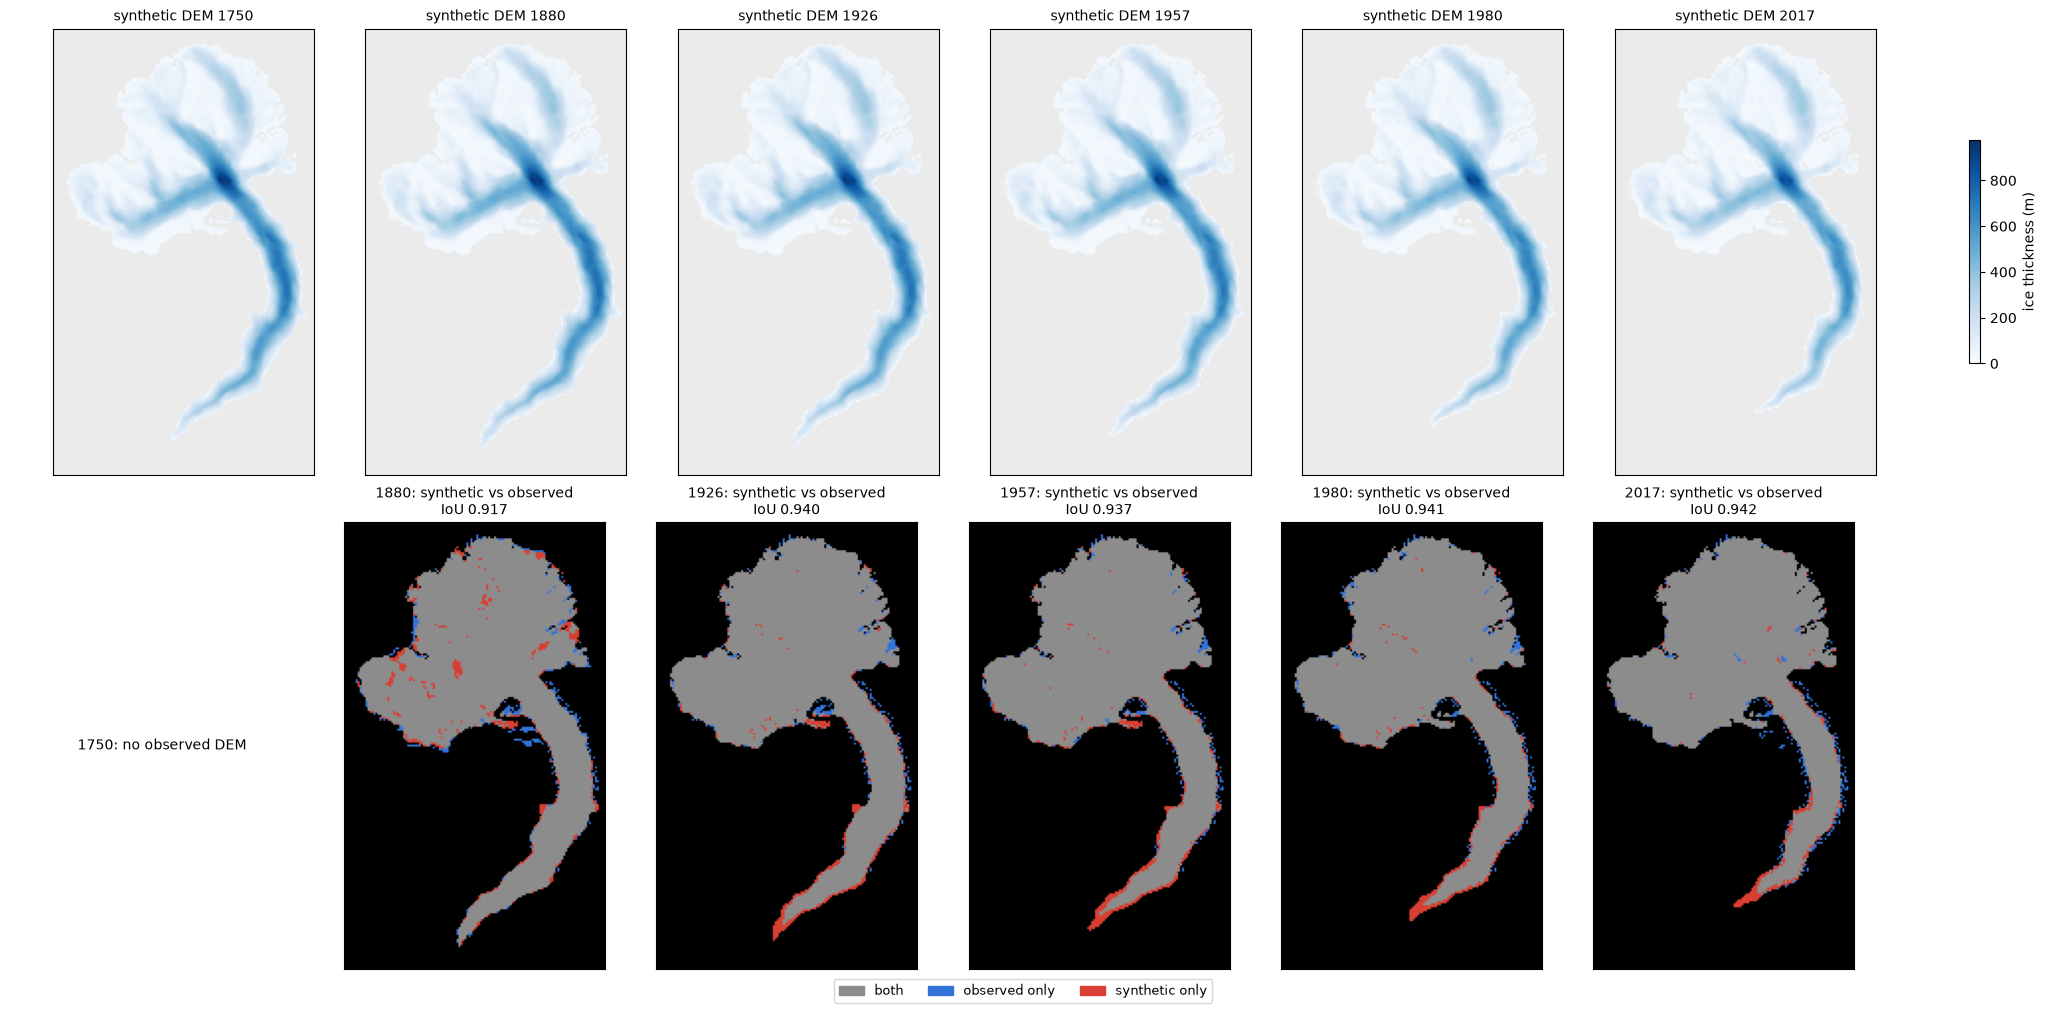

In [6]:
def extent_map(ax, sim, obs, title, thresh=1.0):
    '''Agreement map: grey = both, blue = in `obs` only, red = in `sim` only. Returns the IoU.'''
    s, o = sim > thresh, obs > thresh
    rgb = np.zeros((*s.shape, 3))
    rgb[o & ~s] = [0.20, 0.45, 0.85]
    rgb[s & ~o] = [0.85, 0.25, 0.20]
    rgb[s & o] = [0.55, 0.55, 0.55]
    ax.imshow(rgb, origin="lower", extent=ext, aspect="equal")
    iou = (s & o).sum() / max((s | o).sum(), 1)
    ax.set_title(f"{title}\nIoU {iou:.3f}", fontsize=10)
    ax.set_xticks([]); ax.set_yticks([])
    return iou

def agreement_legend(fig, second):
    colors = [[0.55, 0.55, 0.55], [0.20, 0.45, 0.85], [0.85, 0.25, 0.20]]
    fig.legend([plt.Rectangle((0, 0), 1, 1, color=c) for c in colors],
               ["both", f"{second[0]} only", f"{second[1]} only"],
               loc="outside lower center", ncol=3, fontsize=9)

vmax = max(float(syn_np[y].max()) for y in EPOCHS)
fig, axes = plt.subplots(2, len(EPOCHS), figsize=(3.4 * len(EPOCHS), 10), constrained_layout=True)
for j, y in enumerate(EPOCHS):
    ax = axes[0, j]
    ax.set_facecolor("0.92")
    im = ax.imshow(np.ma.masked_less(syn_np[y], 1.0), origin="lower", extent=ext,
                   cmap="Blues", vmin=0, vmax=vmax, aspect="equal")
    ax.set_title(f"synthetic DEM {y}", fontsize=10)
    ax.set_xticks([]); ax.set_yticks([])
    if y in real_np:
        extent_map(axes[1, j], syn_np[y], real_np[y], f"{y}: synthetic vs observed")
    else:
        axes[1, j].axis("off")
        axes[1, j].text(0.5, 0.5, f"{y}: no observed DEM", ha="center", va="center",
                        transform=axes[1, j].transAxes, fontsize=10)
fig.colorbar(im, ax=axes[0, :], shrink=0.5, label="ice thickness (m)")
agreement_legend(fig, ("observed", "synthetic"))
fig.savefig(f"{RESULTS}/synthetic_dems.png", dpi=150, bbox_inches="tight")
plt.show()

**What this check shows for the default values (6.14 → 7.50 °C).** The extents have the right
*shape* (IoU 0.87-0.88 at every epoch, area 9-12% too large), but the glacier is too cold for
this model's mass balance and the tongue runs into the edge of the model domain. The grid's
boundary condition (`apply_boundary_condition`) ramps ice to zero over the outer 5 rows, and the
synthetic terminus sits there, 0.2 km from the southern edge, **in all five epochs**: about 195 m
of ice reaches the edge in 1880 and still 137 m in 2017. The observed terminus is 1.1 km from the
edge in 1880 and retreats 2.6 km by 2017. Two consequences:

- The synthetic glacier loses 12% of its volume between 1880 and 2017, the real one 34%.
- **The terminus, the part of the extent that responds most directly to temperature, carries no
  signal**, because the domain edge holds it. An extent-only inversion then has much less to
  work with than in the real case. That is a property of the chosen truth, not of the method.

*Why.* 6.14 and 7.50 °C are the temperatures implied by the constant-temperature terminus
analysis (V2), i.e. where an *equilibrium* glacier would end at the observed 1880 and 2017
termini. Here the glacier is run transiently from 1500 with this notebook's `BASE` parameters, and
at ~6.1 °C it grows past the domain. The real-data inversions with the same `BASE` parameters
(V1, V3) found 7.3-8.2 °C for the same period.

*Alternatives, measured.* Same GELU shape (`SHARPNESS = 2`), one forward run each, 10-year
forcing, run outside this notebook with the same code as Section 2. "Terminus" is the
southernmost grid row with ice (1 row = 100 m, row 0 = the southern edge); observed: 11, 22, 27,
32, 37 for 1880, 1926, 1957, 1980, 2017.

| flat → 2017 (°C) | IoU range | terminus row, 1880 … 2017 | volume error, 1880 / 2017 |
|---|---|---|---|
| **6.14 → 7.50** (default) | 0.87-0.88 | 2, 2, 2, 2, 2 (held by the edge) | +19% / +58% |
| 7.0 → 8.2 | 0.90-0.92 | 3, 4, 7, 12, 21 | +1% / +25% |
| 7.2 → 8.2 | 0.92-0.94 | 11, 13, 17, 20, 26 | -6% / +19% |
| 7.3 → 8.5 | 0.92-0.95 | 16, 19, 22, 26, 32 | -9% / +8% |
| **7.4 → 8.8** | 0.91-0.96 | 21, 23, 28, 31, 37 | -13% / -4% |

7.4 → 8.8 °C has the same ~1.4 °C of warming as the default, shifted 1.26 °C warmer. It follows the
observed terminus to within one cell from 1926 on and stays within 4% in area; in 1880 its
terminus is 1 km too far up-valley, because the glacier has not fully regrown to its 1880 extent
from the 2017 start. To use it, set `T_FLAT, T_2017 = 7.40, 8.80` in the setup cell and re-run
from the top.

## 3. The inversion problem

From here on the real DEMs are not used, except for the 2017 geometry that every run starts
from. The observations are `syn`, the synthetic thickness maps at the observation years. The objective is the same
as in the real-data notebook (`core.inversion.invert_extent`): a soft-sigmoid ice indicator
(1 m threshold, 5 m width) compared epoch by epoch, averaged over the epochs, plus
`REG_LAMBDA` times the mean squared difference between neighbouring nodes. Only the *extent* is
fitted, not the thickness.

The control is `T_lowest` on 11 nodes, 1500, 1550, ..., 2000 (the last node also covers
2000-2017). Nothing observes anything before the first epoch (1750), so the earliest nodes are shaped by the
smoothness prior and by the glacier's memory of its initial state, and should be expected to be
the worst recovered.

In [7]:
if RUN_INVERSION:
    glacier = build_glacier(NODE_FREQ)
n_nodes = int((T_END - T_START) // NODE_FREQ) + 1
node_times = [T_START + i * NODE_FREQ for i in range(n_nodes)]
print(f"{n_nodes} control nodes:", node_times)

11 control nodes: [1500, 1550, 1600, 1650, 1700, 1750, 1800, 1850, 1900, 1950, 2000]


## 4. Running the inversion

Adam on the 11 nodes, all epochs weighted equally, every iteration a full forward and
backward pass through 517 simulated years. The loop below writes
`inversion_history.json` after **every** iteration, so a run that is stopped early still leaves
usable results for the sections that follow.

Differences from the loop in the real-data notebook:

- **Initial guess 7.0 °C and learning rate 0.05** (the real-data notebook starts at 7.9 °C with
  0.02). Adam moves a node by at most about `lr` per iteration, so with 0.02 and 60 iterations a
  node can travel only ~1.2 °C in total, while the truth's early nodes are 0.86 °C below the 7.0 °C
  start and 1.76 °C below 7.9 °C. 0.05 leaves room to get there.
- **The stored temperature is the one the loss was evaluated at.** The earlier loop records
  `T` *after* `optimizer.step()`, which is one update ahead of the loss and IoU saved for the same
  iteration, so the "best" temperature it reports is not the one that scored best.
- A non-finite gradient is still dropped before it can reach Adam (see Section 5.1 of the
  real-data notebook).
- After the loop, one extra forward pass evaluates the objective **at the true target nodes**.
  That is the reference point for judging convergence: if the inversion's loss ends *above* the
  loss at the truth the optimiser has not finished; if it ends *below*, the data cannot tell the
  two histories apart.

In [8]:
def save_fields(sim):
    np.savez(f"{RESULTS}/best_fields.npz", x=real["x"], y=real["y"], topg=topg_np,
             **{f"sim_{y}": sim[y].detach().cpu().numpy() for y in EPOCHS},
             **{f"obs_{y}": syn_np[y] for y in EPOCHS})

def save_state():
    with open(f"{RESULTS}/inversion_history.json", "w") as f:
        json.dump(dict(
            settings=dict(t_start=T_START, t_end=T_END, node_freq=NODE_FREQ, truth_freq=TRUTH_FREQ,
                          T_flat=T_FLAT, T_2017=T_2017, sharpness=SHARPNESS, init_T=INIT_T, lr=LR,
                          reg_lambda=REG_LAMBDA, n_iters=N_ITERS),
            base=BASE, node_times=node_times, epochs=EPOCHS,
            truth=dict(years=years.tolist(), T_annual=T_annual.tolist(),
                       T_truth=T_truth.tolist(), T_target=T_target.tolist()),
            history=history, best=best, skipped=skipped, at_target=at_target), f)

forward_kwargs = dict(precip_tensor=BASE["precip"], T_s=BASE["T_s"], melt_factor=BASE["melt_factor"])

if RUN_INVERSION:
    T = torch.full((n_nodes, 1), INIT_T, device=device, requires_grad=True)
    optimizer = torch.optim.Adam([T], lr=LR)
    weights = {y: 1.0 for y in EPOCHS}

    history = dict(loss=[], data=[], T=[], grad_norm=[], seconds=[],
                   iou={y: [] for y in EPOCHS}, area={y: [] for y in EPOCHS})
    best, skipped, at_target = dict(loss=float("inf"), iter=None, T=None), 0, None

    for i in range(N_ITERS):
        t0 = time.time()
        optimizer.zero_grad()
        sim, loss, data_term, metrics = invert_extent(
            T, syn, glacier, weights=weights, reg_lambda=REG_LAMBDA, **forward_kwargs)
        loss.backward()
        grad_norm = float(T.grad.norm())

        # A non-finite gradient must never reach Adam: it writes NaN into T and every later
        # forward pass is NaN. Drop the step instead.
        if not (np.isfinite(grad_norm) and np.isfinite(float(loss))):
            optimizer.zero_grad()
            skipped += 1
            print(f"iter {i:3d}: non-finite gradient (|grad| {grad_norm}) -- step skipped ({skipped} so far)")
            continue

        T_eval = T.detach().cpu().numpy().flatten().tolist()   # the T this loss and IoU belong to
        optimizer.step()
        dt = time.time() - t0

        history["loss"].append(float(loss))
        history["data"].append(float(data_term))
        history["T"].append(T_eval)
        history["grad_norm"].append(grad_norm)
        history["seconds"].append(dt)
        for y in EPOCHS:
            history["iou"][y].append(float(metrics[y]["iou"]))
            history["area"][y].append(float(metrics[y]["area"]))

        if float(loss) < best["loss"]:
            best = dict(loss=float(loss), iter=len(history["loss"]) - 1, T=T_eval)
            save_fields(sim)
        save_state()

        rmse = np.sqrt(np.mean((np.array(T_eval) - T_target) ** 2))
        print(f"iter {i:3d}: loss {float(loss):.5f}  mean IoU "
              f"{np.mean([history['iou'][y][-1] for y in EPOCHS]):.3f}  "
              f"T rmse vs target {rmse:.3f} C  ({dt:.0f}s)", flush=True)

    # The objective at the true target nodes: the yardstick for "has it converged?".
    with torch.no_grad():
        _, loss_ref, data_ref, metrics_ref = invert_extent(
            torch.tensor(T_target, dtype=torch.float32, device=device).view(-1, 1), syn, glacier,
            weights=weights, reg_lambda=REG_LAMBDA, **forward_kwargs)
    at_target = dict(loss=float(loss_ref), data=float(data_ref),
                     iou={y: float(metrics_ref[y]["iou"]) for y in EPOCHS})
    save_state()
    print(f"\n{skipped} of {N_ITERS} iterations skipped on a non-finite gradient.")
    print(f"loss at the true target nodes: {at_target['loss']:.5f}   best loss reached: {best['loss']:.5f}")
else:
    print("Skipped -- loading the cached run below.")

iter   0: loss 0.00537  mean IoU 0.955  T rmse vs target 0.653 C  (196s)
iter   1: loss 0.00464  mean IoU 0.961  T rmse vs target 0.618 C  (206s)
iter   2: loss 0.00392  mean IoU 0.967  T rmse vs target 0.585 C  (194s)
iter   3: loss 0.00327  mean IoU 0.972  T rmse vs target 0.556 C  (206s)
iter   4: loss 0.00296  mean IoU 0.975  T rmse vs target 0.530 C  (191s)
iter   5: loss 0.00267  mean IoU 0.977  T rmse vs target 0.506 C  (201s)
iter   6: loss 0.00251  mean IoU 0.978  T rmse vs target 0.483 C  (185s)
iter   7: loss 0.00238  mean IoU 0.979  T rmse vs target 0.460 C  (188s)
iter   8: loss 0.00227  mean IoU 0.980  T rmse vs target 0.439 C  (186s)
iter   9: loss 0.00215  mean IoU 0.980  T rmse vs target 0.418 C  (185s)
iter  10: loss 0.00209  mean IoU 0.981  T rmse vs target 0.399 C  (213s)
iter  11: loss 0.00207  mean IoU 0.981  T rmse vs target 0.382 C  (189s)
iter  12: loss 0.00196  mean IoU 0.982  T rmse vs target 0.361 C  (186s)
iter  13: loss 0.00182  mean IoU 0.983  T rmse vs t

## 5. Results: convergence

In [9]:
with open(f"{RESULTS}/inversion_history.json") as f:
    run = json.load(f)
h, best, at_target = run["history"], run["best"], run["at_target"]
node_times = run["node_times"]
T_annual = np.array(run["truth"]["T_annual"]); T_truth = np.array(run["truth"]["T_truth"])
T_target = np.array(run["truth"]["T_target"])
years = np.array(run["truth"]["years"])
n_iter = len(h["loss"])
T_hist = np.array(h["T"])                                  # (n_iter, n_nodes), the T each loss belongs to
T_rmse = np.sqrt(((T_hist - T_target) ** 2).mean(axis=1))  # error against the 50-yr target, per iteration
best_T = np.array(best["T"])

print(f"{n_iter} iterations ({run['skipped']} skipped), {len(node_times)} control nodes, "
      f"{np.mean(h['seconds']):.0f} s / iteration")
print(f"best loss {best['loss']:.5f} at iteration {best['iter']}   (first iteration {h['loss'][0]:.5f})")
if at_target is not None:
    print(f"loss at the true target nodes: {at_target['loss']:.5f}   "
          f"-> best is {'ABOVE' if best['loss'] > at_target['loss'] else 'below'} the loss at the truth")
print(f"T rmse against the 50-yr target: {T_rmse[0]:.2f} C at the start -> {T_rmse[best['iter']]:.2f} C at the best iteration")
print()
print(f"{'year':>12}" + "".join(f"{y:>8}" for y in EPOCHS))
print(f"{'IoU (init)':>12}" + "".join(f"{h['iou'][str(y)][0]:8.3f}" for y in EPOCHS))
print(f"{'IoU (best)':>12}" + "".join(f"{h['iou'][str(y)][best['iter']]:8.3f}" for y in EPOCHS))
if at_target is not None:
    print(f"{'IoU (truth)':>12}" + "".join(f"{at_target['iou'][str(y)]:8.3f}" for y in EPOCHS))

50 iterations (0 skipped), 11 control nodes, 189 s / iteration
best loss 0.00059 at iteration 36   (first iteration 0.00537)
loss at the true target nodes: 0.00086   -> best is below the loss at the truth
T rmse against the 50-yr target: 0.65 C at the start -> 0.09 C at the best iteration

        year    1750    1880    1926    1957    1980    2017
  IoU (init)   0.985   0.981   0.970   0.954   0.937   0.905
  IoU (best)   0.998   0.999   0.997   1.000   0.999   0.991
 IoU (truth)   0.992   0.995   0.995   0.999   1.000   0.994


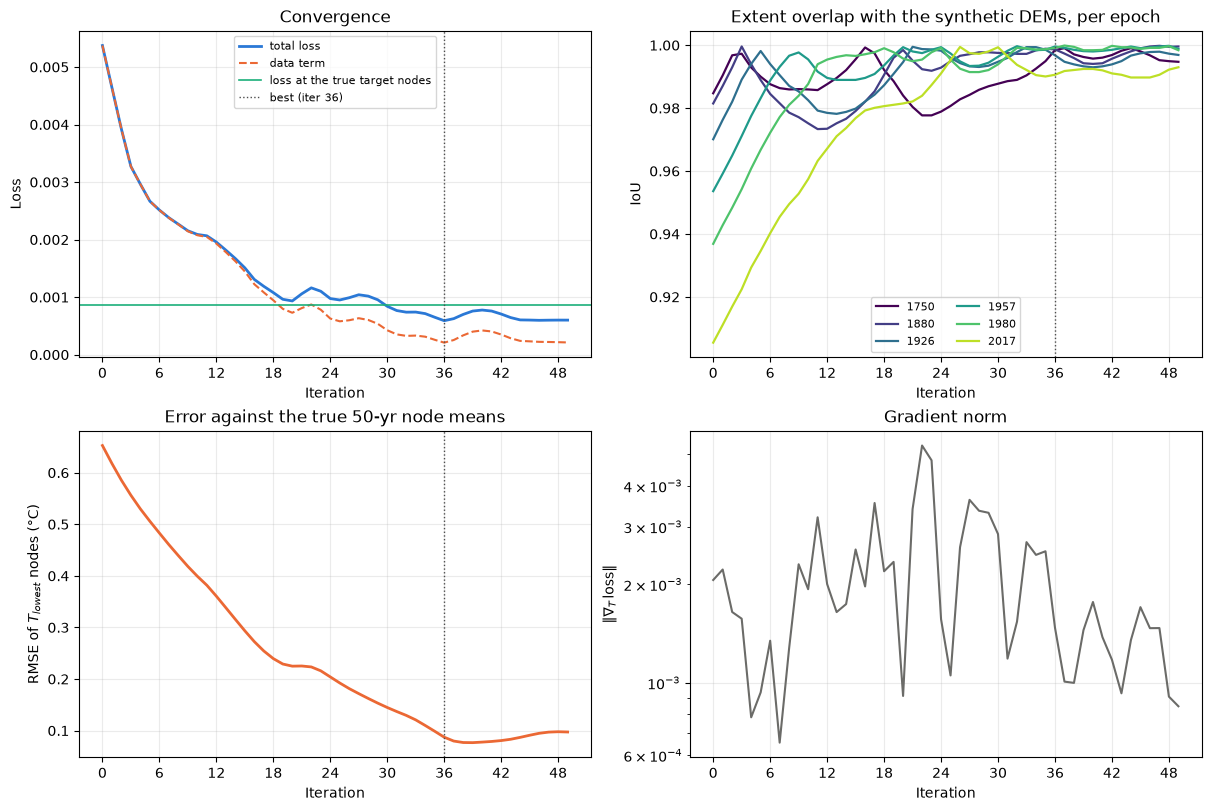

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8), constrained_layout=True)
it = np.arange(n_iter)

ax = axes[0, 0]
ax.plot(it, h["loss"], color=C_TRUE, lw=2, label="total loss")
ax.plot(it, h["data"], color=C_REC, lw=1.5, ls="--", label="data term")
if at_target is not None:
    ax.axhline(at_target["loss"], color=C_TARGET, lw=1.2, label="loss at the true target nodes")
ax.axvline(best["iter"], color="0.3", ls=":", lw=1, label=f"best (iter {best['iter']})")
ax.set(xlabel="Iteration", ylabel="Loss", title="Convergence")
ax.legend(fontsize=8); ax.grid(alpha=0.25)

ax = axes[0, 1]
for y, c in zip(EPOCHS, plt.cm.viridis(np.linspace(0, 0.9, len(EPOCHS)))):
    ax.plot(it, h["iou"][str(y)], color=c, lw=1.6, label=str(y))
ax.axvline(best["iter"], color="0.3", ls=":", lw=1)
ax.set(xlabel="Iteration", ylabel="IoU", title="Extent overlap with the synthetic DEMs, per epoch")
ax.legend(fontsize=8, ncol=2); ax.grid(alpha=0.25)

ax = axes[1, 0]
ax.plot(it, T_rmse, color=C_REC, lw=2)
ax.axvline(best["iter"], color="0.3", ls=":", lw=1)
ax.set(xlabel="Iteration", ylabel="RMSE of $T_{lowest}$ nodes (°C)",
       title="Error against the true 50-yr node means")
ax.grid(alpha=0.25)

ax = axes[1, 1]
ax.plot(it, h["grad_norm"], color=C_GREY, lw=1.5)
ax.set(xlabel="Iteration", ylabel=r"$\|\nabla_T\,\mathrm{loss}\|$", title="Gradient norm", yscale="log")
ax.grid(alpha=0.25)

from matplotlib.ticker import MaxNLocator
for a in axes.flat:
    a.xaxis.set_major_locator(MaxNLocator(integer=True))   # iteration counts are integers
fig.savefig(f"{RESULTS}/inversion_convergence.png", dpi=150, bbox_inches="tight")
plt.show()

## 6. Results: the inverted temperature against the truth

The bold black line is the true temperature and the bold orange line the inverted temperature at
the best-loss iteration. The thin lines behind it are the inferred temperature at **every**
iteration, coloured from the first (purple) to the last (yellow), so the whole path of the
inversion is visible. The triangles on the bottom edge mark the years of the observed extents; at
each of them the error bar runs from the true to the inverted temperature, with the signed
difference (inverted minus true) printed above it.

The inversion controls 11 nodes, 50 years apart, and the model holds each node constant over its
interval. To draw a continuous line, the nodes are joined linearly at the centre of their
intervals (flat before the first and after the last centre), so the lines show a smoothed view of
what the model was given.

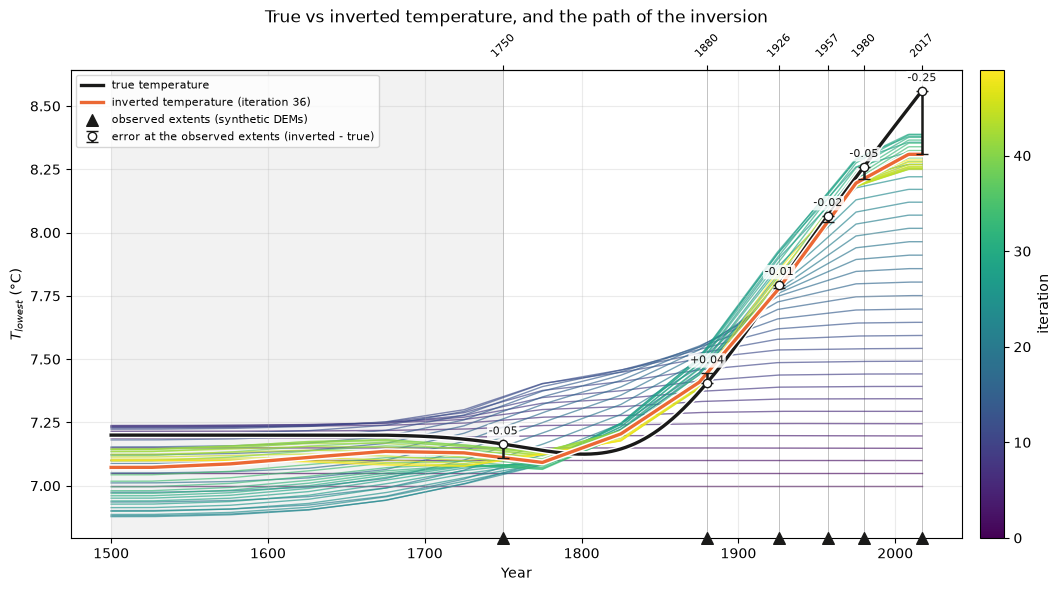

  year    true  inverted   error
  1750    7.16      7.11   -0.05
  1880    7.41      7.45   +0.04
  1926    7.79      7.78   -0.01
  1957    8.07      8.04   -0.02
  1980    8.26      8.21   -0.05
  2017    8.56      8.31   -0.25

RMSE 1500-1749 (before the first observation): 0.09 C   mean error -0.09 C
RMSE 1750-2017 (observed period):               0.07 C   mean error -0.01 C
warming, mean of 1500-1749 -> 2017:  true 1.36 C   inverted 1.20 C   (88% of the true rise)


In [11]:
import matplotlib.patheffects as pe

nt = np.array(node_times)
mid = (nt + np.minimum(nt + NODE_FREQ, T_END)) / 2     # centre of each node's interval (the last is 2000-2017)

def curve(T_nodes):
    '''Continuous line through the node values, joined linearly at the interval centres.'''
    return np.interp(years, mid, T_nodes)

C_INK = "#1a1a19"
rec = curve(best_T)
true_at = np.array([T_annual[years == y][0] for y in EPOCHS])
rec_at = np.array([rec[years == y][0] for y in EPOCHS])
diff = rec_at - true_at

fig, ax = plt.subplots(figsize=(10.5, 5.8), constrained_layout=True)
ax.axvspan(T_START, EPOCHS[0], color="0.5", alpha=0.10, lw=0)

# the inferred temperature at every iteration, first (purple) to last (yellow)
cmap = plt.cm.viridis
top = max(n_iter - 1, 1)
for i in range(n_iter):
    ax.plot(years, curve(T_hist[i]), color=cmap(i / top), lw=1.0, alpha=0.65, zorder=1)
fig.colorbar(plt.cm.ScalarMappable(cmap=cmap, norm=plt.Normalize(0, top)), ax=ax, label="iteration", pad=0.02)

halo = [pe.withStroke(linewidth=4.5, foreground="white")]
ax.plot(years, T_annual, color=C_INK, lw=2.4, path_effects=halo, zorder=4, label="true temperature")
ax.plot(years, rec, color=C_REC, lw=2.4, path_effects=halo, zorder=5,
        label=f"inverted temperature (iteration {best['iter']})")

# the observed extents, and how far the inverted temperature is from the truth at each of them
for y in EPOCHS:
    ax.axvline(y, color="0.3", lw=0.6, alpha=0.4, zorder=0)
ax.scatter(EPOCHS, np.zeros(len(EPOCHS)), transform=ax.get_xaxis_transform(), marker="^", s=70,
           color=C_INK, clip_on=False, zorder=7, label="observed extents (synthetic DEMs)")
ax.errorbar(EPOCHS, true_at, yerr=[np.maximum(-diff, 0), np.maximum(diff, 0)], fmt="o", ms=6,
            mfc="white", mec=C_INK, color=C_INK, ecolor=C_INK, elinewidth=1.8, capsize=4, zorder=6,
            label="error at the observed extents (inverted - true)")
for y, upper, d in zip(EPOCHS, np.maximum(true_at, rec_at), diff):
    ax.annotate(f"{d:+.2f}", (y, upper), xytext=(0, 7), textcoords="offset points", ha="center",
                fontsize=8, color=C_INK, zorder=8,
                bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.85))

sec = ax.secondary_xaxis("top", functions=(lambda v: v, lambda v: v)); sec.set_xticks(EPOCHS); sec.tick_params(labelrotation=45, labelsize=8)
ax.set_xlabel("Year")
ax.set_ylabel("$T_{lowest}$ (°C)")
ax.set_title("True vs inverted temperature, and the path of the inversion", pad=34)
ax.grid(alpha=0.25)
ax.legend(fontsize=8, loc="upper left")
fig.savefig(f"{RESULTS}/temperature_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"{'year':>6}{'true':>8}{'inverted':>10}{'error':>8}")
for y, t, r, d in zip(EPOCHS, true_at, rec_at, diff):
    print(f"{y:>6}{t:8.2f}{r:10.2f}{d:+8.2f}")

err = rec - T_annual
before, observed = years < EPOCHS[0], years >= EPOCHS[0]
print()
print(f"RMSE {years[0]}-{EPOCHS[0] - 1} (before the first observation): {np.sqrt(np.mean(err[before] ** 2)):.2f} C   "
      f"mean error {err[before].mean():+.2f} C")
print(f"RMSE {EPOCHS[0]}-{years[-1]} (observed period):               {np.sqrt(np.mean(err[observed] ** 2)):.2f} C   "
      f"mean error {err[observed].mean():+.2f} C")
base = years < 1750
rise_true, rise_rec = T_annual[-1] - T_annual[base].mean(), rec[-1] - rec[base].mean()
print(f"warming, mean of {years[0]}-1749 -> {years[-1]}:  true {rise_true:.2f} C   inverted {rise_rec:.2f} C   "
      f"({rise_rec / rise_true * 100:.0f}% of the true rise)")

## 7. Results: simulated vs synthetic extent, at the best iteration

Same colour code as Section 2.1, but now the comparison is between what the inverted
temperature history produces (red = simulated only) and the synthetic DEM it was fitted to
(blue = synthetic only). The table adds what an extent-only objective does *not* see: volume.

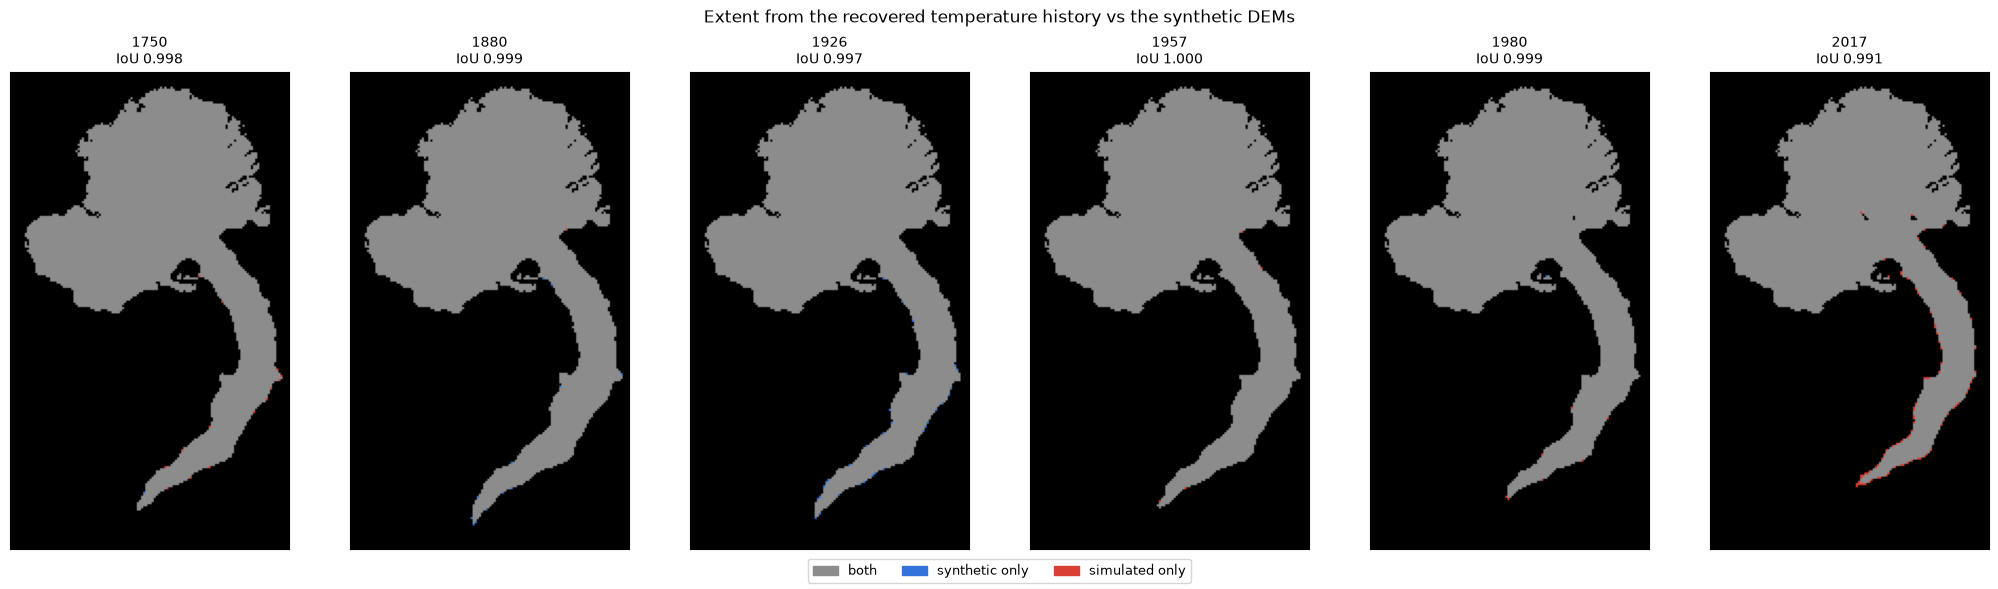

  year     IoU          area km2          volume km3  volume error
                    sim    synth       sim     synth
  1750   0.998     96.1     96.0     19.02     18.94         +0.5%
  1880   0.999     97.4     97.5     19.33     19.53         -1.0%
  1926   0.997     96.4     96.7     18.51     18.70         -1.0%
  1957   1.000     95.2     95.2     17.71     17.68         +0.2%
  1980   0.999     93.7     93.6     16.76     16.73         +0.2%
  2017   0.991     91.5     90.6     15.44     14.92         +3.5%


In [12]:
fields = np.load(f"{RESULTS}/best_fields.npz")
fig, axes = plt.subplots(1, len(EPOCHS), figsize=(3.4 * len(EPOCHS), 5.8), constrained_layout=True)
for ax, y in zip(axes, EPOCHS):
    extent_map(ax, fields[f"sim_{y}"], fields[f"obs_{y}"], str(y))
agreement_legend(fig, ("synthetic", "simulated"))
fig.suptitle("Extent from the recovered temperature history vs the synthetic DEMs", fontsize=12)
fig.savefig(f"{RESULTS}/extent_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"{'year':>6}{'IoU':>8}{'area km2':>18}{'volume km3':>20}{'volume error':>14}")
print(f"{'':>6}{'':>8}{'sim':>9}{'synth':>9}{'sim':>10}{'synth':>10}")
for y in EPOCHS:
    sim, obs = fields[f"sim_{y}"], fields[f"obs_{y}"]
    s, o = sim > 1, obs > 1
    vs, vo = sim.sum() * 1e-5, obs.sum() * 1e-5
    print(f"{y:>6}{(s & o).sum() / (s | o).sum():8.3f}{s.sum() * 0.01:9.1f}{o.sum() * 0.01:9.1f}"
          f"{vs:10.2f}{vo:10.2f}{(vs / vo - 1) * 100:+13.1f}%")

## 8. Where to take this next

- **Break the identical-model assumption.** Re-run the inversion with the melt factor,
  precipitation or tau_ref perturbed (the sensitivity study in the real-data notebook gives the
  expected temperature bias per % error). That separates the part of the real-data error that is
  physics from the part that is the observations.
- **Change the truth.** `T_FLAT`, `T_2017` and `SHARPNESS` in the setup cell define the true
  climate; Section 2.1 says how close the resulting geometries are to Aletsch. A truth that
  warms earlier than the hockey stick used here would also test whether the 50-year nodes can
  follow a faster change.
- **Add a thickness epoch.** Section 7's volume column is the information extent-only data
  leave out; weighting one thickness observation would show how much of it the temperature
  history can recover.